# Лабораторная работа №10. Часть 1: Данные `trees`

**Задание:**
1. Выведите имена столбцов таблицы `trees`.
2. С помощью теста Шапиро-Уилка проверьте на нормальность каждый столбец таблицы. Сделайте выводы.
3. С помощью критерия Фишера проверьте гипотезы о независимости переменных. Сделайте выводы.

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Создаем папку для картинок, если ее нет
os.makedirs("output", exist_ok=True)
ALPHA = 0.05

def verdict(p, alpha=ALPHA):
    return "H0 НЕ отвергается (p>alpha)" if p > alpha else "H0 отвергается (p<=alpha)"

### Загрузка данных

Это классический датасет из книги Weiss, "Introductory Statistics". В 1970-х годах измерили 31 вишневое дерево (Black Cherry Trees), чтобы понять, как связаны размеры дерева с его объемом.


In [4]:
def load_data():
    local_file = "trees.csv"
    if os.path.exists(local_file):
        df = pd.read_csv(local_file)
    else:
        url = "https://vincentarelbundock.github.io/Rdatasets/csv/datasets/trees.csv"
        df = pd.read_csv(url)
    # Убираем служебный столбец rownames, если он есть
    df = df.drop(columns=[c for c in df.columns if c.lower().startswith("row")], errors="ignore")
    return df

trees = load_data()

### 1. Имена столбцов


Girth (Диаметр) — обхват ствола дерева в дюймах. Значения от 8.3 до 20.6. Это толщина дерева.

Height (Высота) — высота дерева в футах. Значения от 63 до 87.

Volume (Объем) — объем древесины в кубических футах. Значения от 10.2 до 77.0.

In [5]:
print("[1] Имена столбцов таблицы trees:")
print(list(trees.columns))
trees.head()

[1] Имена столбцов таблицы trees:
['Girth', 'Height', 'Volume']


,Girth,Height,Volume
0,8.3,70,10.3
1,8.6,65,10.3
2,8.8,63,10.2
3,10.5,72,16.4
4,10.7,81,18.8


### 2. Тест Шапиро-Уилка (нормальность)

Здесь мы проверяем, можно ли вообще применять параметрические тесты к этим данным

**H0:** данные распределены нормально.  
**H1:** данные распределены не нормально.  
При `p > 0.05` нет оснований отвергать H0 (считаем нормальными).

H0 (Нулевая гипотеза)?
H0 (H-zero) — это всегда гипотеза «скучного сценария». Она гласит: «Всё нормально, никаких эффектов нет, различий нет, всё одинаково, признаки независимы».

Когда мы говорим «H0 о равенстве», мы имеем в виду:

«Средние значения равны» (например, в ldeaths: смертность в 1974 году = смертности в 1975);

«Дисперсии равны» (например, в trees: разброс у Girth = разбросу у Height).
«Распределения одинаковые»

Суть: H0 всегда предполагает, что ничего интересного не происходит. Это как «презумпция невиновности» в суде.

In [6]:
print("[2] Тест Шапиро-Уилка на нормальность")
print(f"{'Столбец':<10} | {'W':>8} | {'p-value':>10} | Вывод")
print("-" * 60)

sw_results = {}
for col in trees.columns:
    W, p = stats.shapiro(trees[col])
    sw_results[col] = (W, p)
    print(f"{col:<10} | {W:>8.4f} | {p:>10.4g} | {verdict(p)}")

[2] Тест Шапиро-Уилка на нормальность
Столбец    |        W |    p-value | Вывод
------------------------------------------------------------
Girth      |   0.9412 |    0.08893 | H0 НЕ отвергается (p>alpha)
Height     |   0.9655 |     0.4034 | H0 НЕ отвергается (p>alpha)
Volume     |   0.8876 |   0.003579 | H0 отвергается (p<=alpha)


**Вывод по п.2:**
* `Girth` (p = 0.089) и `Height` (p = 0.403) — H0 **не отвергается**, данные можно считать нормальными.
* `Volume` (p = 0.0036) — H0 **отвергается**, распределение значимо отличается от нормального.

Выборка маленькая (n=31). При малых n тест Шапиро-Уилка имеет низкую мощность (часто «пропускает» ненормальность). Отсутствие значимости ≠ доказанная нормальность. Кроме того, параметры при KS-тесте оцениваются по выборке (Lilliefors-проблема), поэтому Shapiro-Wilk предпочтительнее.

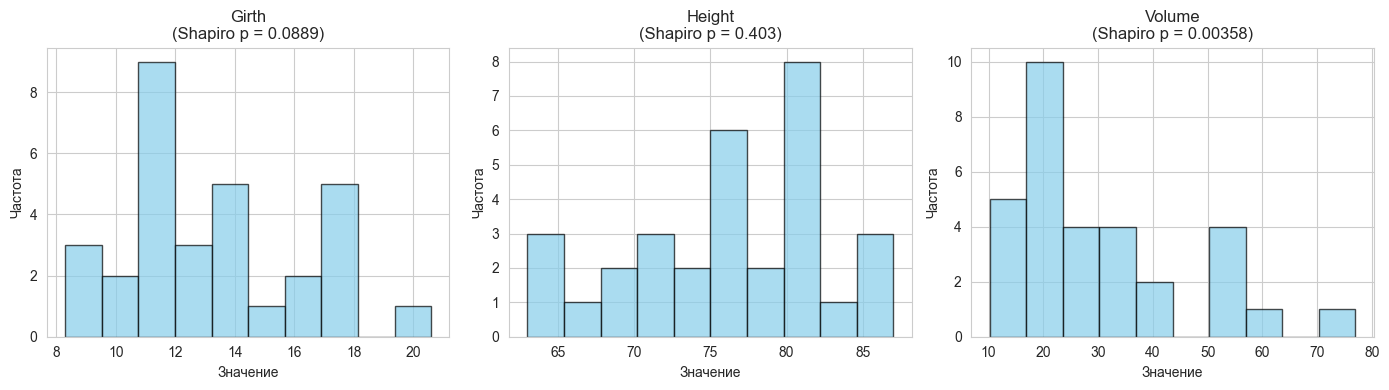

In [8]:
# Визуализация: гистограммы для наглядности
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, trees.columns):
    ax.hist(trees[col], bins=10, edgecolor="k", alpha=0.7, color="skyblue")
    ax.set_title(f"{col}\n(Shapiro p = {sw_results[col][1]:.3g})")
    ax.set_xlabel("Значение")
    ax.set_ylabel("Частота")
plt.tight_layout()
# plt.savefig("output/trees_hist.png", dpi=120)
plt.show()

### 3. Критерий Фишера (равенство дисперсий / независимость)

Критерий Фишера — это математический способ проверить: разброс реально разный, или просто случайность?

В статистике «разброс» называется дисперсией (variance).

H0 (Нулевая гипотеза): Дисперсии равны (... одинаково стабильны).
H1 (Альтернатива): Дисперсии различаются

**H0:** дисперсии равны (σ₁² = σ₂²).  
**H1:** дисперсии различаются.  
*Примечание:* В задании написано «независимость», но F-тест Фишера проверяет именно **равенство дисперсий**. Для проверки истинной независимости (корреляции) мы дополнительно выведем матрицу корреляций.

Здесь мы проверяем «разброс» данных (дисперсию).

H0 (Нулевая): Дисперсии двух столбцов равны. То есть данные разбросаны одинаково.
H1 (Альтернативная): Дисперсии не равны

Главный смысл: Чем толще дерево (Girth), тем больше в нем кубов древесины (Volume). На это указывает корреляция 0.967 (почти 1). А вот высота (Height) связана с объемом гораздо слабее (0.598).

Из-за разницы в единицах измерения (дюймы vs футы) дисперсии у столбцов кардинально разные. Поэтому критерий Фишера отвергнет равенство дисперсий. И именно поэтому Volume распределен не нормально (он растет экспоненциально от диаметра).

In [9]:
def f_test(a, b):
    """Двусторонний F-тест равенства дисперсий"""
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    F = a.var(ddof=1) / b.var(ddof=1)
    dfn, dfd = len(a) - 1, len(b) - 1
    cdf = stats.f.cdf(F, dfn, dfd)
    p = 2 * min(cdf, 1 - cdf)
    return F, p, dfn, dfd

print("[3] Критерий Фишера: попарное сравнение дисперсий")
cols = list(trees.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        a, b = trees[cols[i]], trees[cols[j]]
        F, p, dfn, dfd = f_test(a, b)
        print(f"  {cols[i]:<8} vs {cols[j]:<8} | F = {F:8.4f} | df = ({dfn}, {dfd}) | p = {p:.4g} | {verdict(p)}")

print("\nМатрица корреляций (для проверки истинной независимости):")
print(trees.corr().round(3))

[3] Критерий Фишера: попарное сравнение дисперсий
  Girth    vs Height   | F =   0.2426 | df = (30, 30) | p = 0.0002127 | H0 отвергается (p<=alpha)
  Girth    vs Volume   | F =   0.0364 | df = (30, 30) | p = 1.509e-14 | H0 отвергается (p<=alpha)
  Height   vs Volume   | F =   0.1503 | df = (30, 30) | p = 1.381e-06 | H0 отвергается (p<=alpha)

Матрица корреляций (для проверки истинной независимости):
        Girth  Height  Volume
Girth   1.000   0.519   0.967
Height  0.519   1.000   0.598
Volume  0.967   0.598   1.000


дисперсия — это краеугольный камень всей статистики. Если среднее значение показывает «центр» данных, то дисперсия показывает, насколько сильно данные разлетаются от этого центра

Если мы берем дисперсию Girth (толщина в дюймах), числа там маленькие, и отклонения маленькие (квадраты маленькие).
Если мы берем Volume (объем в кубических футах), числа огромные (до 77), отклонения большие, и при возведении в квадрат они становятся просто гигантскими.

Поэтому дисперсия Volume в десятки раз больше дисперсии Girth. F-тест это видит и говорит: "Парень, да у тебя дисперсии вообще разные, H0 отвергается".

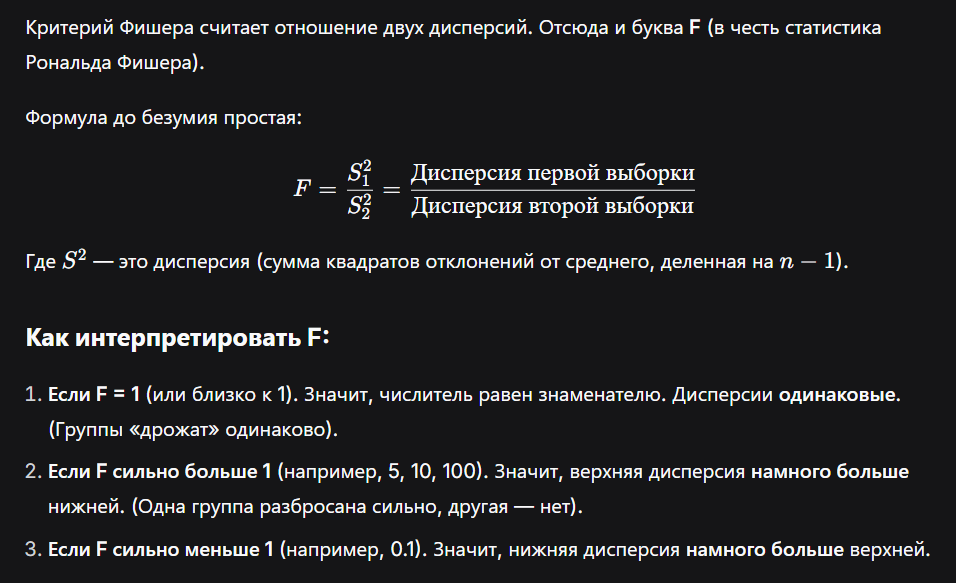

центр данных — это «типичное» или «главное» значение, вокруг которого группируются все остальные числа в выборке.

Простыми словами: если тебе нужно описать всю группу данных одним числом, ты ищешь их центр.

Но вот незадача: в статистике есть три разных способа найти этот центр, и они могут давать разные ответы. На защите это спрашивают очень часто

Среднее арифметическое (Mean)
Это то, что мы все учили в школе: сложить всё и поделить на количество.

Смысл: «Точка равновесия» или центр тяжести данных.

Формула: 
x
ˉ
=
∑
x
i
n
x
ˉ
 = 
n
∑x 
i
​
 
​
  (сумма всех значений, деленная на их количество).

Плюс: Использует всю информацию.

Минус (важно!): Очень чувствительно к выбросам. Если у тебя зарплаты 20, 30, 40, 50 и 1000000, среднее будет 200028. Это не отражает реальность.

Медиана (Median)
Это значение, которое находится ровно посередине, если отсортировать данные по возрастанию.

Смысл: 50% данных меньше медианы, 50% — больше.

Как искать: Отсортируй числа. Возьми то, что в центре (если чисел четное количество — возьми среднее двух центральных).

Плюс: Не боится выбросов (робастна). В примере с зарплатами медиана будет 40. Это гораздо честнее.

Минус: Не использует всю информацию (неважно, насколько огромный выброс, медиана от него не сдвинется).

Мода (Mode)
Это значение, которое встречается чаще всего.

Смысл: Самый популярный вариант.

Пример: Размер обуви (38, 39, 39, 42, 39). Мода — 39.

Плюс: Работает даже для категориальных данных (например, «любимый цвет» или «марка машины»).

Минус: Может быть несколько мод или их вообще не быть.

**Вывод по п.3:**
* Все пары имеют `p < 0.05`, следовательно, H0 о равенстве дисперсий **отвергается**. Дисперсии значимо различаются (что логично, так как переменные измерены в разных единицах: дюймы, футы, кубические футы).
* **Про независимость:** Матрица корреляций показывает, что `Girth` и `Volume` сильно связаны (r = 0.967), а `Height` слабее связан с ними (r ~ 0.5). Это означает, что переменные **зависимы**.
* *Ограничение F-теста:* он очень чувствителен к нарушению нормальности (а `Volume` у нас не нормален). В таких случаях робастнее использовать тест **Levene** или **Bartlett**.